# 📈 Modul Praktik: Linear Regression (Salary Prediction)

Selamat datang di lembar kerja praktik **Linear Regression**! Notebook ini telah disiapkan untuk alur kerja Machine Learning yang rapi:
1. **Import Library & Utilitas**
2. **Load & Eksplorasi Dataset** (`Salary_Data.csv`)
3. **Pembersihan & Validasi Data** (Missing values, duplikat, tipe data)
4. **Visualisasi Data (EDA)** (Scatter plot, distribusi, korelasi)
5. **Feature & Target Splitting + Train-Test Split** (80% Data Latih : 20% Data Uji)
6. **🎯 Lembar Kerja Latihan Modelling** (Disisakan khusus untuk kamu praktik langsung!)

---


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi style grafik agar bersih dan estetik
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 11

print("✅ Semua library berhasil diimpor!")


✅ Semua library berhasil diimpor!


## 1. Load Dataset
Memuat dataset `Salary_Data.csv` yang berisi data pengalaman kerja (`YearsExperience`) dan gaji (`Salary`).


In [2]:
# Membaca dataset
data_path = 'Salary_Data.csv'
df = pd.read_csv(data_path)

print(f"Dimensi Data: {df.shape[0]} baris, {df.shape[1]} kolom")
df.head(10)


Dimensi Data: 30 baris, 2 kolom


,YearsExperience,Salary
0,1.2,39344.0
1,1.4,46206.0
2,1.6,37732.0
3,2.1,43526.0
4,2.3,39892.0
5,3.0,56643.0
6,3.1,60151.0
7,3.3,54446.0
8,3.3,64446.0
9,3.8,57190.0


## 2. Pembersihan & Pengecekan Data (Data Cleaning)
Sebelum data dilatih ke model machine learning, kita harus memvalidasi:
- Apakah terdapat *missing values* (nilai kosong)?
- Apakah terdapat data duplikat?
- Apakah tipe data sudah berupa numerik?
- Bagaimana distribusi statistik dasarnya?


In [3]:
# 1. Informasi Struktur Data & Tipe Data
print("=== INFORMASI STRUKTUR DATA ===")
df.info()

# 2. Pengecekan Missing Values
print("\n=== JUMLAH MISSING VALUES ===")
missing_count = df.isnull().sum()
print(missing_count)

# 3. Pengecekan Duplikasi Baris
print("\n=== JUMLAH DUPLIKAT ===")
duplicates_count = df.duplicated().sum()
print(f"Total baris duplikat: {duplicates_count}")

# 4. Ringkasan Statistik Deskriptif
print("\n=== STATISTIK DESKRIPTIF ===")
df.describe()


=== INFORMASI STRUKTUR DATA ===
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes

=== JUMLAH MISSING VALUES ===
YearsExperience    0
Salary             0
dtype: int64

=== JUMLAH DUPLIKAT ===
Total baris duplikat: 0

=== STATISTIK DESKRIPTIF ===


,YearsExperience,Salary
count,30.000000,30.000000
mean,5.413333,76004.000000
std,2.837888,27414.429785
min,1.200000,37732.000000
25%,3.300000,56721.750000
50%,4.800000,65238.000000
75%,7.800000,100545.750000
max,10.600000,122392.000000


> 💡 **Kesimpulan Pembersihan Data:**
> - Dataset memiliki **30 baris data** tanpa ada nilai kosong (**0 Missing Values**).
> - **Tidak ada data duplikat** (**0 Duplikat**).
> - Kedua kolom bertipe `float64` (numerik kontinu), yang langsung siap untuk pemodelan regresi.


## 3. Visualisasi Data (Exploratory Data Analysis - EDA)
Mari kita amati pola persebaran data dan hubungan antara `YearsExperience` dengan `Salary`.


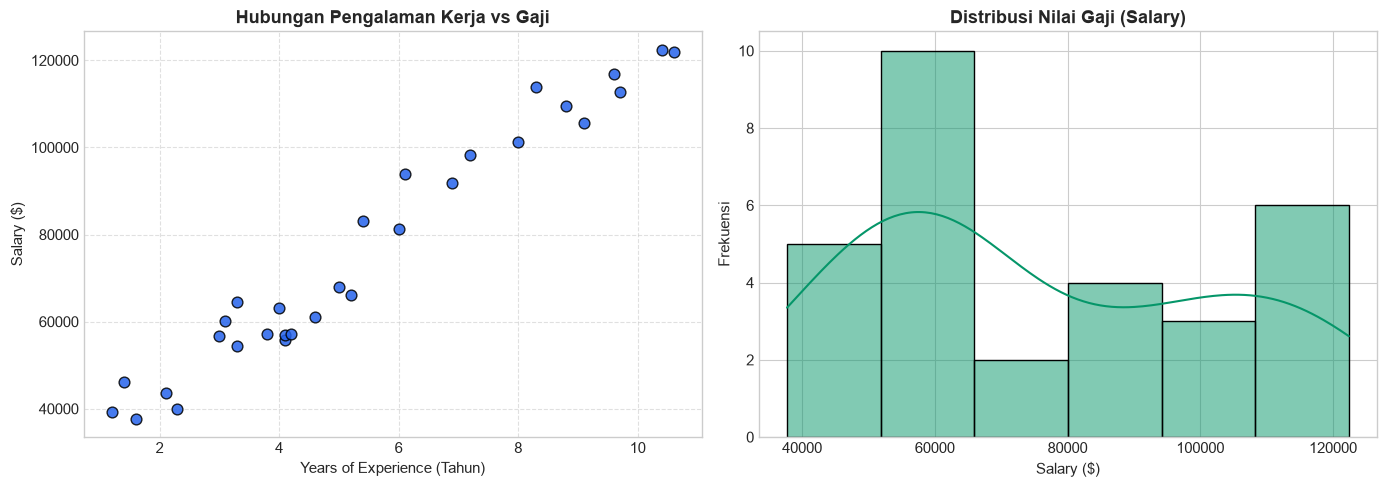

=== MATRIKS KORELASI PEARSON ===
                 YearsExperience    Salary
YearsExperience         1.000000  0.978242
Salary                  0.978242  1.000000

Nilai Korelasi: 0.9782 (Sangat Kuat & Positif Linier)


In [4]:
# Visualisasi Hubungan Fitur & Target
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Scatter Plot Hubungan Fitur vs Target
axes[0].scatter(df['YearsExperience'], df['Salary'], color='#2563EB', s=60, edgecolors='black', alpha=0.85)
axes[0].set_title('Hubungan Pengalaman Kerja vs Gaji', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Years of Experience (Tahun)', fontsize=11)
axes[0].set_ylabel('Salary ($)', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot 2: Distribusi Target (Salary)
sns.histplot(df['Salary'], kde=True, color='#059669', ax=axes[1])
axes[1].set_title('Distribusi Nilai Gaji (Salary)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Salary ($)', fontsize=11)
axes[1].set_ylabel('Frekuensi', fontsize=11)

plt.tight_layout()
plt.show()

# Pengecekan Matriks Korelasi Pearson
corr = df.corr()
print("=== MATRIKS KORELASI PEARSON ===")
print(corr)
print(f"\nNilai Korelasi: {corr.iloc[0, 1]:.4f} (Sangat Kuat & Positif Linier)")


## 4. Feature Selection & Train-Test Split
Kita pisahkan:
- **Fitur Independen ($X$)**: `YearsExperience` (sebagai input/prediktor)
- **Variabel Target ($y$)**: `Salary` (sebagai label yang ingin diprediksi)

Kemudian kita bagi menjadi:
- **Data Latih (Train)**: 80% (24 baris) untuk melatih model
- **Data Uji (Test)**: 20% (6 baris) untuk menguji performa model


In [5]:
from sklearn.model_selection import train_test_split

# 1. Pisahkan Fitur (X) dan Target (y)
X = df[['YearsExperience']]  # Format 2D DataFrame (30, 1) untuk Scikit-Learn
y = df['Salary']             # Format 1D Series (30,) untuk target

# 2. Split Data (80% Train, 20% Test, random_state=42 agar reproducible)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Verifikasi ukuran split
print(f"Total Sampel       : {len(df)}")
print(f"Jumlah Data Latih  : {len(X_train)} sampel (80%)")
print(f"Jumlah Data Uji    : {len(X_test)} sampel (20%)")
print(f"Bentuk X_train     : {X_train.shape}")
print(f"Bentuk y_train     : {y_train.shape}")
print(f"Bentuk X_test      : {X_test.shape}")
print(f"Bentuk y_test      : {y_test.shape}")


Total Sampel       : 30
Jumlah Data Latih  : 24 sampel (80%)
Jumlah Data Uji    : 6 sampel (20%)
Bentuk X_train     : (24, 1)
Bentuk y_train     : (24,)
Bentuk X_test      : (6, 1)
Bentuk y_test      : (6,)


### Cuplikan Sampel Data Latih & Data Uji
Mari intip data yang masuk ke data latih dan data uji:


In [6]:
print("--- 5 Sampel Pertama Data Latih (X_train & y_train) ---")
display(pd.concat([X_train, y_train], axis=1).head())

print("\n--- Seluruh Data Uji (X_test & y_test) ---")
display(pd.concat([X_test, y_test], axis=1))


--- 5 Sampel Pertama Data Latih (X_train & y_train) ---


,YearsExperience,Salary
28,10.4,122392.0
24,8.8,109432.0
12,4.1,56958.0
0,1.2,39344.0
4,2.3,39892.0



--- Seluruh Data Uji (X_test & y_test) ---


,YearsExperience,Salary
27,9.7,112636.0
15,5.0,67939.0
23,8.3,113813.0
17,5.4,83089.0
8,3.3,64446.0
9,3.8,57190.0


---
## 🎯 5. AREA LATIHAN KAMU: MODELLING LINEAR REGRESSION
Dataset sudah siap digunakan! Sekarang giliranmu berlatih memodelkan regresi linier.

### 📋 Panduan Pengerjaan:
1. **Inisialisasi & Latih Model**:
   - Gunakan `from sklearn.linear_model import LinearRegression` *(atau implementasi manual `LinearRegressionManual`)*
   - Latih model menggunakan `model.fit(X_train, y_train)`
2. **Cek Koefisien**:
   - Ambil kemiringan garis (`model.coef_`) dan intercept (`model.intercept_`)
3. **Lakukan Prediksi**:
   - Hitung prediksi untuk data uji: `y_pred = model.predict(X_test)`
4. **Evaluasi Metrik**:
   - Hitung metrik evaluasi regresi:
     - **$R^2$ Score** (`r2_score`)
     - **MAE** (`mean_absolute_error`)
     - **RMSE** (`root_mean_squared_error` atau `np.sqrt(mean_squared_error)`)
5. **Visualisasi Garis Regresi**:
   - Tampilkan scatter plot data aktual (`X_test`, `y_test`) dan garis regresi (`X_test`, `y_pred`).

---
*(Tulis kodemu di cell latihan di bawah ini)* 👇


In [7]:

# ==========================================
# 1. INISIALISASI & FIT MODEL
# ==========================================
# TODO: Inisialisasi model LinearRegression dan latih dengan X_train & y_train


w = 9400
b = 25000


def prediksi (x,w,b):
    return w * x + b

def cost (x,y,w,b):
    x = np.array(x).flatten()
    y = np.array(y).flatten()
    m = len(x)
    print(m)
    prediksian = prediksi (x,w,b)
    error = prediksian - y
    cost = (1 / (2 * m)) * np.sum(error ** 2)
   
  
    return cost
    

hasil = cost(X_train, y_train, w, b)
print("Hasil Cost:", hasil)

    



24
Hasil Cost: 13675435.1875


In [8]:
# ==========================================
# 2. PREDIKSI & EVALUASI PERFORMA
# ==========================================
# TODO: Lakukan prediksi pada X_test dan hitung skor evaluasi (R2, MAE, RMSE)

# --- TULIS KODEMU DI SINI ---


In [9]:
# ==========================================
# 3. VISUALISASI HASIL REGRESI
# ==========================================
# TODO: Buat visualisasi scatter data uji dan garis regresi (best-fit line)

# --- TULIS KODEMU DI SINI ---


<details>
<summary><b>💡 Klik di sini jika butuh Bantuan / Solusi Referensi (Hint)</b></summary>

```python
# 1. Training Model
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

model = LinearRegression()
model.fit(X_train, y_train)

print(f"Slope (w)     : {model.coef_[0]:.2f}")
print(f"Intercept (b) : {model.intercept_:.2f}")

# 2. Prediksi & Evaluasi
y_pred = model.predict(X_test)
print(f"R² Score : {r2_score(y_test, y_pred):.4f}")
print(f"MAE      : {mean_absolute_error(y_test, y_pred):.2f}")
print(f"RMSE     : {root_mean_squared_error(y_test, y_pred):.2f}")

# 3. Visualisasi Garis Regresi
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color='blue', label='Data Aktual (Uji)', s=60)
plt.plot(X_test, y_pred, color='red', linewidth=2, label='Garis Regresi Model')
plt.title('Hasil Prediksi Regresi Linier vs Data Aktual')
plt.xlabel('Years of Experience')
plt.ylabel('Salary ($)')
plt.legend()
plt.show()
```
</details>
